# Module 01: Electric Field Explorer — Flagship Laboratory

## Introduction & Learning Objectives
Welcome to **Invisible Physics**. In this flagship laboratory notebook, we explore the electrostatic vector field $\mathbf{E}(\mathbf{r})$ produced by stationary point charges in two dimensions.

**Learning Objectives:**
1. Compute and visualize 2D electrostatic vector fields using Coulomb's law and linear superposition.
2. Distinguish between electric-field direction (unit vectors and continuous streamlines) and field magnitude $|\mathbf{E}|$.
3. Analyze seven fundamental charge topologies: single positive charge, single negative charge, electric dipole, two like charges, two unequal opposite charges, a symmetric four-charge quadrupole, and custom multi-charge arrangements.
4. Understand why classical point charges produce mathematical singularities as $\|\mathbf{r} - \mathbf{r}_i\| \to 0$ and how documented regularization strategies (`core_cutoff`, `softening`, `mask`) preserve numerical stability.

---

## Physical Model, Units & Equations

For $N$ stationary point charges $q_i$ located at positions $\mathbf{r}_i = (x_i, y_i)$ in free space, the electric field $\mathbf{E}(\mathbf{r})$ at evaluation coordinate $\mathbf{r} = (x, y)$ is governed by **Coulomb's Law**:

$$\mathbf{E}(\mathbf{r}) = \frac{1}{4\pi\varepsilon_0} \sum_{i=1}^{N} q_i \frac{\mathbf{r} - \mathbf{r}_i}{\|\mathbf{r} - \mathbf{r}_i\|^3}$$

### Variables and SI Units
- $q_i$: Charge value input in microcoulombs ($\mu\text{C}$) and converted internally to coulombs ($1\ \mu\text{C} = 10^{-6}\ \text{C}$).
- $\mathbf{r} = (x, y)$: Evaluation coordinates in meters ($\text{m}$).
- $\varepsilon_0 = 8.8541878188 \times 10^{-12}\ \text{F/m}$: Vacuum electric permittivity (NIST CODATA 2022).
- $k_e = (4\pi\varepsilon_0)^{-1} \approx 8.98755 \times 10^9\ \text{N}\cdot\text{m}^2/\text{C}^2$: Coulomb constant.
- $\mathbf{E} = (E_x, E_y)$: Electric-field vector in volts per meter ($\text{V/m}$, equivalent to $\text{N/C}$).
- $r_{\min} = 0.05\ \text{m}$: Documented singularity cutoff radius around each idealized point charge.

In [6]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))

import numpy as np
import matplotlib.pyplot as plt

from invisible_physics import (
    COULOMB_K,
    EPSILON_0,
    PointCharge,
    apply_scientific_style,
    create_coordinate_grid,
    electric_field_2d,
    electric_potential_2d,
    get_preset_charges,
    plot_combined_field_and_potential,
    plot_electric_field_heatmap,
    plot_electric_field_streamlines,
    plot_electric_field_vectors,
    plot_potential_surface_3d,
)

apply_scientific_style()
print(f"Coulomb constant k_e = {COULOMB_K:.6e} N·m²/C²")
print(f"Vacuum permittivity eps_0 = {EPSILON_0:.6e} F/m")

Coulomb constant k_e = 8.987552e+09 N·m²/C²
Vacuum permittivity eps_0 = 8.854188e-12 F/m


---
## 1. Single Positive vs. Single Negative Point Charge

A single point charge produces an isotropic radial field whose magnitude decays as the inverse square of distance ($|\mathbf{E}| \propto 1/r^2$):
- For a **positive charge** ($+1.0\ \mu\text{C}$, red circle with `+`), field lines diverge radially outward.
- For a **negative charge** ($-1.0\ \mu\text{C}$, blue square with `−`), field lines converge radially inward.

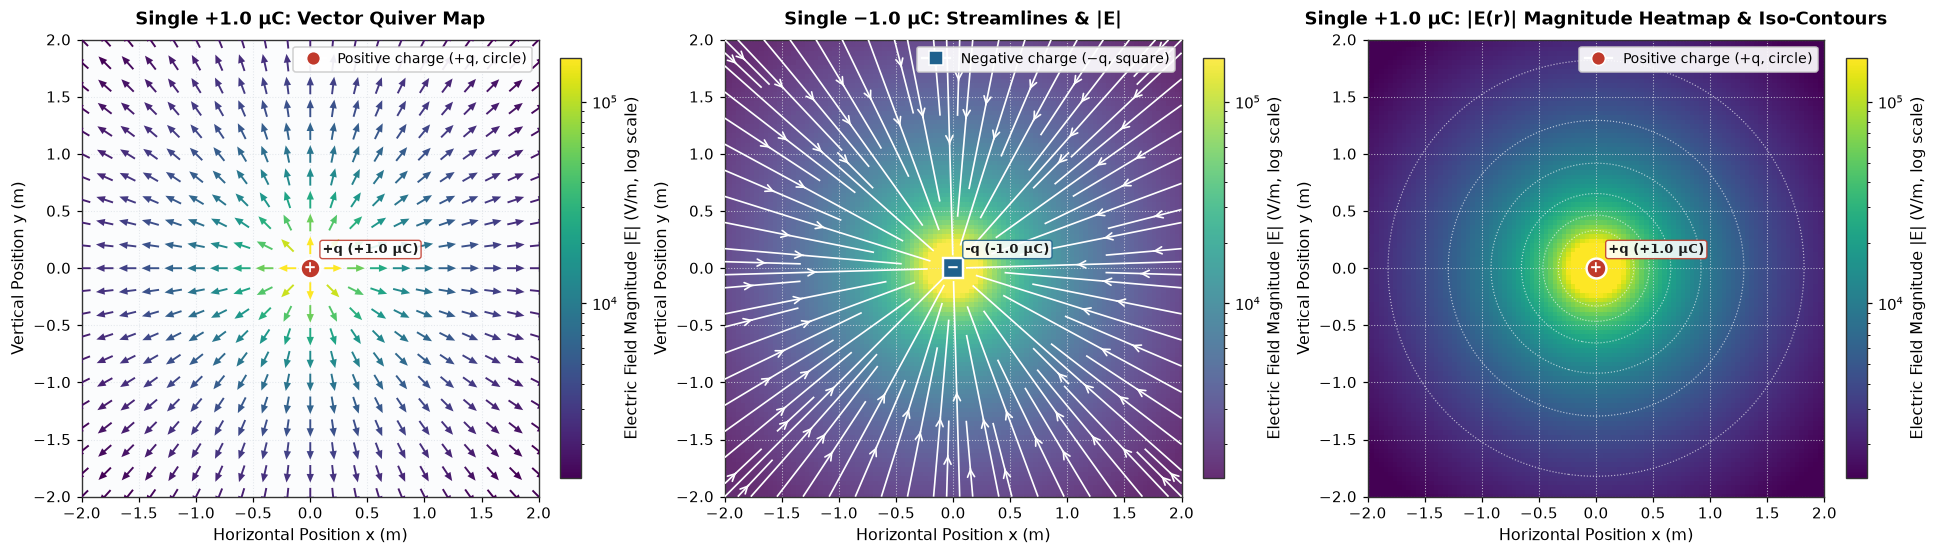

Computed |E| at r = 1.0 m for +1.0 μC : 8987.5518 V/m (Analytical: 8987.5518 V/m)


In [7]:
X, Y = create_coordinate_grid(x_lim=(-2.0, 2.0), y_lim=(-2.0, 2.0), n_points=101)

pos_charge = get_preset_charges("single_positive", scale_q_uc=1.0)
neg_charge = get_preset_charges("single_negative", scale_q_uc=1.0)

field_pos = electric_field_2d(X, Y, pos_charge, r_min=0.05, strategy="core_cutoff")
field_neg = electric_field_2d(X, Y, neg_charge, r_min=0.05, strategy="core_cutoff")

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2), constrained_layout=True)
plot_electric_field_vectors(
    field_pos, pos_charge, ax=axes[0], stride=5,
    title="Single +1.0 μC: Vector Quiver Map"
)
plot_electric_field_streamlines(
    field_neg, neg_charge, ax=axes[1], density=1.2,
    title="Single −1.0 μC: Streamlines & |E|"
)
plot_electric_field_heatmap(
    field_pos, pos_charge, ax=axes[2],
    title="Single +1.0 μC: |E(r)| Magnitude Heatmap & Iso-Contours"
)
plt.show()

r_eval = 1.0
e_1m = electric_field_2d(np.array([r_eval]), np.array([0.0]), pos_charge).E_mag[0]
print(f"Computed |E| at r = 1.0 m for +1.0 μC : {e_1m:.4f} V/m (Analytical: {COULOMB_K * 1e-6:.4f} V/m)")

### Interpretation
Notice that the magnitudes $|\mathbf{E}(r)|$ in the left and right panels are identical at equal radial distances ($8.988 \times 10^3\ \text{V/m}$ at $r = 1.0\ \text{m}$), while the vector directions are reversed ($180^\circ$). Positive and negative charges are distinguished by both marker shape (circle vs. square), internal symbol (`+` vs. `−`), and explicit text labels.

---
## 2. Two-Charge Configurations: Dipole, Like Charges, and Unequal Opposite Charges

By the **principle of linear superposition**, the net electric field of multiple charges is the vector sum of their individual fields. Let us compare three fundamental two-charge topologies side by side:
1. **Electric Dipole ($+1\ \mu\text{C}, -1\ \mu\text{C}$)**: Field lines originate on $+q$ and terminate on $-q$.
2. **Two Like Positive Charges ($+1\ \mu\text{C}, +1\ \mu\text{C}$)**: Field lines repel near the origin, creating an exact saddle null point ($\mathbf{E} = \mathbf{0}$) at the midpoint $(0, 0)$.
3. **Unequal Opposite Charges ($+2\ \mu\text{C}, -1\ \mu\text{C}$)**: Half of the flux leaving $+2q$ terminates on $-q$, while the remaining flux escapes to infinity; an off-center null point forms to the right of $-q$.

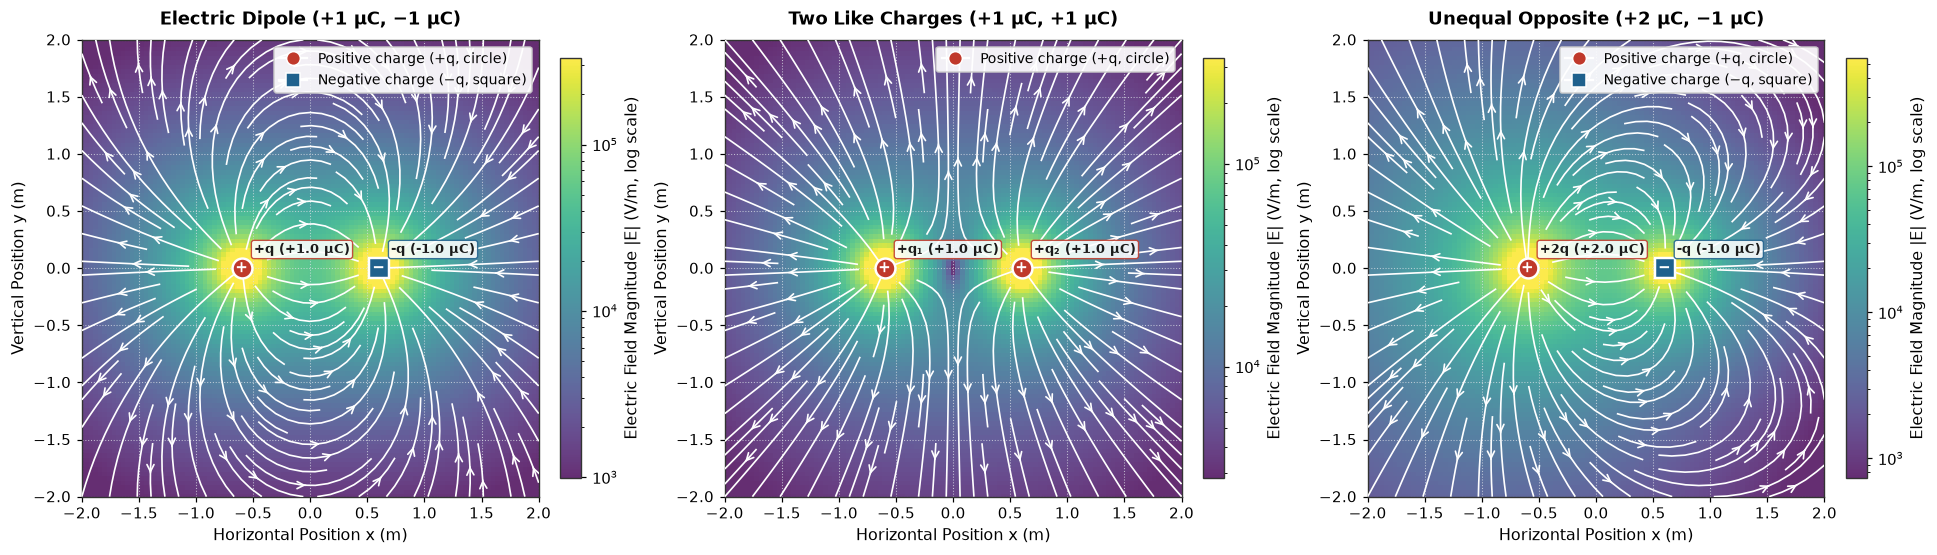

In [8]:
configs = [
    ("dipole", "Electric Dipole (+1 μC, −1 μC)"),
    ("two_like_positive", "Two Like Charges (+1 μC, +1 μC)"),
    ("unequal_opposite", "Unequal Opposite (+2 μC, −1 μC)"),
]

fig, axes = plt.subplots(1, 3, figsize=(17.5, 5.2), constrained_layout=True)
for ax, (preset_key, title_str) in zip(axes, configs):
    charges = get_preset_charges(preset_key, scale_q_uc=1.0, separation_m=1.2)
    f_res = electric_field_2d(X, Y, charges, r_min=0.05)
    plot_electric_field_streamlines(f_res, charges, ax=ax, density=1.15, title=title_str)

plt.show()

### Interpretation
- In the **dipole** panel, the vertical midplane $x = 0$ is an equipotential surface ($V = 0$) where the vertical component $E_y$ cancels identically and $\mathbf{E}$ points purely in the $+x$ direction.
- In the **two like charges** panel, streamlines bend sharply away from the origin $(0, 0)$, visually confirming the electrostatic repulsion and the zero-field stagnation point at the center.
- In the **unequal opposite** panel, the asymmetry between $+2.0\ \mu\text{C}$ and $-1.0\ \mu\text{C}$ shifts the stagnation point to the exterior of the weaker charge at $x_{\text{null}} = a(\sqrt{2}+1)/(\sqrt{2}-1) \approx +3.497\ \text{m}$ (or closer when separation is reduced).

---
## 3. Symmetric Four-Charge Quadrupole & Combined Field-Potential View

Next, we examine a **symmetric four-charge quadrupole** ($+q, -q, +q, -q$ arranged at the corners of a square) and a **three-charge triangular configuration**, combining electric-field streamlines with scalar potential $V(\mathbf{r})$ and dashed equipotential contours.

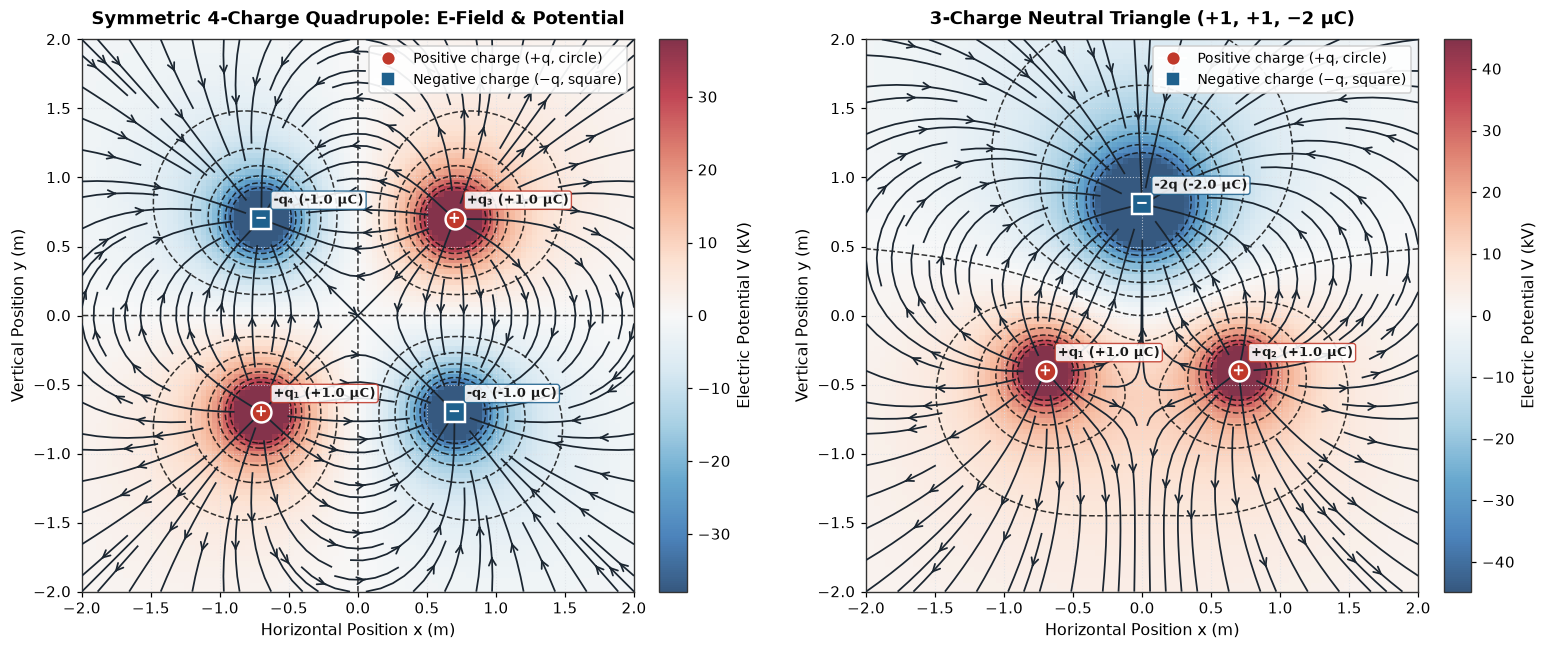

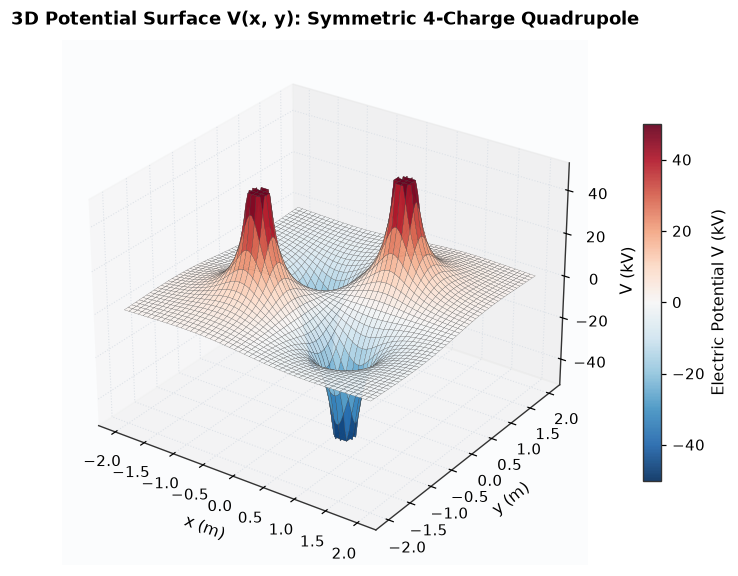

Quadrupole center (0, 0): |E| = 0.000e+00 V/m, V = 0.000e+00 V


In [9]:
quad_charges = get_preset_charges("symmetric_quadrupole", scale_q_uc=1.0, separation_m=1.4)
tri_charges = get_preset_charges("three_charge_triangle", scale_q_uc=1.0, separation_m=1.4)

f_quad = electric_field_2d(X, Y, quad_charges)
v_quad = electric_potential_2d(X, Y, quad_charges)

f_tri = electric_field_2d(X, Y, tri_charges)
v_tri = electric_potential_2d(X, Y, tri_charges)

fig, axes = plt.subplots(1, 2, figsize=(14.2, 5.8), constrained_layout=True)
plot_combined_field_and_potential(
    f_quad, v_quad, quad_charges, ax=axes[0],
    title="Symmetric 4-Charge Quadrupole: E-Field & Potential"
)
plot_combined_field_and_potential(
    f_tri, v_tri, tri_charges, ax=axes[1],
    title="3-Charge Neutral Triangle (+1, +1, −2 μC)"
)
plt.show()

fig_3d, _ = plot_potential_surface_3d(
    v_quad, title="3D Potential Surface V(x, y): Symmetric 4-Charge Quadrupole"
)
plt.show()

center_e = electric_field_2d(np.array([0.0]), np.array([0.0]), quad_charges).E_mag[0]
center_v = electric_potential_2d(np.array([0.0]), np.array([0.0]), quad_charges).V[0]
print(f"Quadrupole center (0, 0): |E| = {center_e:.3e} V/m, V = {center_v:.3e} V")

### Interpretation
At every intersection in both plots, the solid electric-field streamlines cross the dashed equipotential contours at **right angles ($90^\circ$)**, illustrating $\mathbf{E} = -\nabla V$. For the symmetric quadrupole, both $V(0, 0) = 0\ \text{V}$ and $|\mathbf{E}(0, 0)| = 0\ \text{V/m}$ vanish at the origin by four-fold alternating symmetry.

---
## 4. Interactive Multi-Charge Explorer (`ipywidgets`)

Use the interactive laboratory controls below to adjust charge magnitudes ($q_1, q_2, q_3 \in [-5, +5]\ \mu\text{C}$), positions ($x_i, y_i \in [-1.6, +1.6]\ \text{m}$), visualization mode, and singularity strategy. A **Reset to Dipole** button restores default parameters.

> **Frontend Note**: Interactive sliders require an active Jupyter kernel with `ipywidgets` enabled (standard in JupyterLab 4+ and VS Code). When viewed statically (e.g., on GitHub), the default rendered output is shown automatically.

Output()

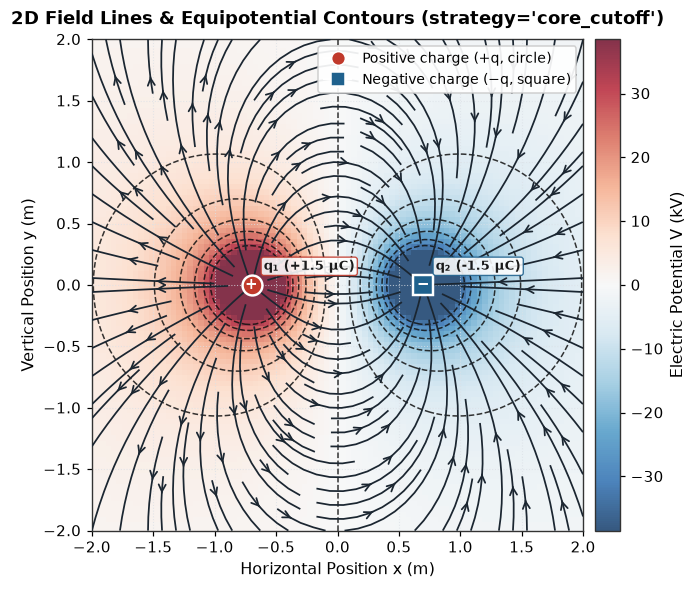

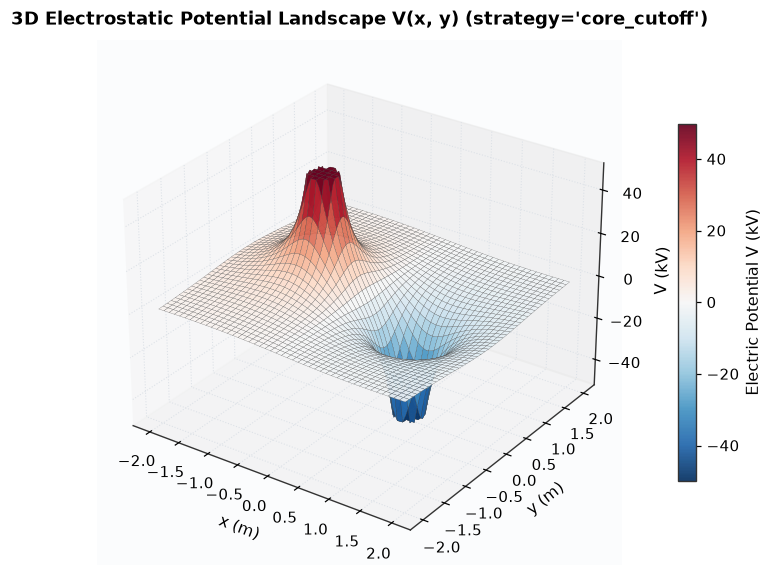

In [11]:
import sys
from pathlib import Path
for _cand in (Path.cwd() / "src", Path.cwd().parent / "src"):
    if _cand.is_dir() and str(_cand.resolve()) not in sys.path:
        sys.path.insert(0, str(_cand.resolve()))
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from IPython.display import display
from invisible_physics import *


def render_interactive_field_explorer(
    q1_uc: float = 1.5,
    x1_m: float = -0.7,
    y1_m: float = 0.0,
    q2_uc: float = -1.5,
    x2_m: float = 0.7,
    y2_m: float = 0.0,
    q3_uc: float = 0.0,
    x3_m: float = 0.0,
    y3_m: float = 0.9,
    view_mode: str = "2D Streamlines + 3D Potential Surface",
    strategy: str = "core_cutoff",
) -> None:
    grid_x, grid_y = create_coordinate_grid((-2.0, 2.0), (-2.0, 2.0), n_points=91)
    active_charges = [
        PointCharge(q_uc=q1_uc, x=x1_m, y=y1_m, label="q₁"),
        PointCharge(q_uc=q2_uc, x=x2_m, y=y2_m, label="q₂"),
    ]
    if abs(q3_uc) > 1e-6:
        active_charges.append(PointCharge(q_uc=q3_uc, x=x3_m, y=y3_m, label="q₃"))

    f_res = electric_field_2d(grid_x, grid_y, active_charges, r_min=0.05, strategy=strategy)
    v_res = electric_potential_2d(grid_x, grid_y, active_charges, r_min=0.05, strategy=strategy)

    if view_mode == "2D Streamlines + 3D Potential Surface":
        fig, ax2d = plt.subplots(1, 1, figsize=(7.2, 5.8))
        plot_combined_field_and_potential(
            f_res, v_res, active_charges, ax=ax2d,
            title=f"2D Field Lines & Equipotential Contours (strategy='{strategy}')"
        )
        plt.show()
        plot_potential_surface_3d(
            v_res, title=f"3D Electrostatic Potential Landscape V(x, y) (strategy='{strategy}')"
        )
        plt.show()
    elif view_mode == "Vector Quiver Plot":
        plot_electric_field_vectors(
            f_res, active_charges, stride=4,
            title=f"2D Electric Field Vectors (strategy='{strategy}')"
        )
        plt.show()
    elif view_mode == "|E| Magnitude Heatmap":
        plot_electric_field_heatmap(
            f_res, active_charges,
            title=f"2D Electric Field Magnitude Heatmap (strategy='{strategy}')"
        )
        plt.show()
    elif view_mode == "3D Potential Surface Only":
        plot_potential_surface_3d(
            v_res, title=f"3D Electrostatic Potential Landscape V(x, y) (strategy='{strategy}')"
        )
        plt.show()
    else:
        plot_electric_field_streamlines(
            f_res, active_charges,
            title=f"2D Electric Field Streamlines (strategy='{strategy}')"
        )
        plt.show()


q1_slider = widgets.FloatSlider(value=1.5, min=-5.0, max=5.0, step=0.1, description="q₁ (μC):")
x1_slider = widgets.FloatSlider(value=-0.7, min=-1.6, max=1.6, step=0.1, description="x₁ (m):")
y1_slider = widgets.FloatSlider(value=0.0, min=-1.6, max=1.6, step=0.1, description="y₁ (m):")

q2_slider = widgets.FloatSlider(value=-1.5, min=-5.0, max=5.0, step=0.1, description="q₂ (μC):")
x2_slider = widgets.FloatSlider(value=0.7, min=-1.6, max=1.6, step=0.1, description="x₂ (m):")
y2_slider = widgets.FloatSlider(value=0.0, min=-1.6, max=1.6, step=0.1, description="y₂ (m):")

q3_slider = widgets.FloatSlider(value=0.0, min=-5.0, max=5.0, step=0.1, description="q₃ (μC):")
x3_slider = widgets.FloatSlider(value=0.0, min=-1.6, max=1.6, step=0.1, description="x₃ (m):")
y3_slider = widgets.FloatSlider(value=0.9, min=-1.6, max=1.6, step=0.1, description="y₃ (m):")

mode_dropdown = widgets.Dropdown(
    options=[
        "2D Streamlines + 3D Potential Surface",
        "Streamlines + |E| Heatmap",
        "Vector Quiver Plot",
        "|E| Magnitude Heatmap",
        "3D Potential Surface Only",
    ],
    value="2D Streamlines + 3D Potential Surface",
    description="View Mode:",
)
strategy_dropdown = widgets.Dropdown(
    options=["core_cutoff", "softening", "mask"],
    value="core_cutoff",
    description="Singularity:",
)
reset_btn = widgets.Button(description="Reset to Dipole", button_style="info")


def _on_reset(_: widgets.Button) -> None:
    q1_slider.value, x1_slider.value, y1_slider.value = 1.5, -0.7, 0.0
    q2_slider.value, x2_slider.value, y2_slider.value = -1.5, 0.7, 0.0
    q3_slider.value, x3_slider.value, y3_slider.value = 0.0, 0.0, 0.9
    mode_dropdown.value = "2D Streamlines + 3D Potential Surface"
    strategy_dropdown.value = "core_cutoff"


reset_btn.on_click(_on_reset)

ui = widgets.VBox([
    widgets.HBox([q1_slider, x1_slider, y1_slider]),
    widgets.HBox([q2_slider, x2_slider, y2_slider]),
    widgets.HBox([q3_slider, x3_slider, y3_slider]),
    widgets.HBox([mode_dropdown, strategy_dropdown, reset_btn]),
])
out = widgets.interactive_output(
    render_interactive_field_explorer,
    {
        "q1_uc": q1_slider, "x1_m": x1_slider, "y1_m": y1_slider,
        "q2_uc": q2_slider, "x2_m": x2_slider, "y2_m": y2_slider,
        "q3_uc": q3_slider, "x3_m": x3_slider, "y3_m": y3_slider,
        "view_mode": mode_dropdown, "strategy": strategy_dropdown,
    },
)
display(ui, out)
# Also render the default 2D + 3D analysis directly so it is always visible even before running widgets
render_interactive_field_explorer()

---
## Summary & Further Experiments
- **What we learned**: Electrostatic fields obey linear superposition, diverge from positive charges, converge on negative charges, and scale as $1/r^2$ from isolated point sources.
- **Next steps**: Proceed to [`02_electric_potential_landscape.ipynb`](02_electric_potential_landscape.ipynb) to explore scalar potential hills and wells in 2D and 3D and quantitatively validate $\mathbf{E} = -\nabla V$.
- **Reference**: Griffiths, D. J., *Introduction to Electrodynamics*, 4th ed., Chapter 2 (Electrostatics).